# Playground: Land Subsidence Susceptibility Mapping (Tulare-Corcoran, San Joaquin Valley)

Module 7 warm-up for Milestone 3. This notebook loads the project's grid-cell dataset and takes a first look at it.

**Dataset:** `data/subsidence_dataset.csv`, one row per ~500 m grid cell, built by `build_dataset.py` from real public sources (see README for sources, retrieval date and licenses).
**Status:** the InSAR displacement label is not included yet (the DWR InSAR rasters are hosted on a Box page rather than a direct download, so I am working from the point data instead). This notebook covers the predictor features.

## 1. Setup

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 4)

## 2. Retrieve the dataset
The file lives in this repository's `data/` folder (about 1.6 MB, built from public sources). It is loaded by a relative path, so the notebook runs top to bottom on any machine with the repo checked out. To rebuild it from the original sources, run `python build_dataset.py`.

In [3]:
DATA_PATH = "data/subsidence_dataset.csv"
df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH!r}")

Loaded 'data/subsidence_dataset.csv'


## 3. Basic dataset information

In [4]:
print(f"Rows (grid cells): {df.shape[0]}")
print(f"Columns (fields):  {df.shape[1]}")

Rows (grid cells): 5192
Columns (fields):  30


In [5]:
df.dtypes

longitude                        float64
latitude                         float64
grid_id                              str
cdl_code_2016                    float64
cdl_code_2017                    float64
cdl_code_2018                    float64
cdl_code_2019                    float64
land_use_name_last_year              str
n_years_cropped                    int64
n_years_fallow                     int64
is_perennial_crop                  int64
land_use_changed                   int64
mukey                            float64
drainagecl                           str
hydgrp                               str
taxclname                            str
clay_pct                         float64
sand_pct                         float64
silt_pct                         float64
organic_matter_pct               float64
ksat_um_per_s                    float64
available_water_capacity         float64
elevation_m                      float64
slope_deg                        float64
gw_decline_m_per

In [6]:
df.head(5)

,longitude,latitude,grid_id,cdl_code_2016,cdl_code_2017,cdl_code_2018,cdl_code_2019,land_use_name_last_year,n_years_cropped,n_years_fallow,is_perennial_crop,land_use_changed,mukey,drainagecl,hydgrp,taxclname,clay_pct,sand_pct,silt_pct,organic_matter_pct,ksat_um_per_s,available_water_capacity,elevation_m,slope_deg,gw_decline_m_per_yr_2016_2019,gw_mean_depth_m,gw_latest_depth_m,gw_depth_std_m,gw_n_measurements,dist_to_nearest_well_m
0,-119.697979,36.002714,TC-00000,2.0,54.0,54.0,54.0,tomatoes,4,0,0,1,461824.0,Somewhat poorly drained,C,"Fine, smectitic, calcareous, thermic Vertic En...",70.0,1.0,29.0,2.5,0.5,0.14,55.690575,0.048636,1.508458,60.514992,63.5508,2.164896,5,25469.0
1,-119.692555,36.003816,TC-00001,54.0,54.0,33.0,2.0,cotton,3,0,0,1,461824.0,Somewhat poorly drained,C,"Fine, smectitic, calcareous, thermic Vertic En...",70.0,1.0,29.0,2.5,0.5,0.14,55.638206,0.043523,1.508458,60.514992,63.5508,2.164896,5,25102.0
2,-119.687131,36.004918,TC-00002,54.0,54.0,54.0,2.0,cotton,4,0,0,1,461824.0,Somewhat poorly drained,C,"Fine, smectitic, calcareous, thermic Vertic En...",70.0,1.0,29.0,2.5,0.5,0.14,55.392876,0.085388,1.508458,60.514992,63.5508,2.164896,5,24740.0
3,-119.681707,36.006019,TC-00003,54.0,54.0,54.0,2.0,cotton,4,0,0,1,461824.0,Somewhat poorly drained,C,"Fine, smectitic, calcareous, thermic Vertic En...",70.0,1.0,29.0,2.5,0.5,0.14,54.923828,0.058444,1.508458,60.514992,63.5508,2.164896,5,24383.0
4,-119.676283,36.007120,TC-00004,2.0,33.0,2.0,2.0,cotton,3,0,0,1,461824.0,Somewhat poorly drained,C,"Fine, smectitic, calcareous, thermic Vertic En...",70.0,1.0,29.0,2.5,0.5,0.14,54.597633,0.030231,1.508458,60.514992,63.5508,2.164896,5,24031.0


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,5192.0,-119.501626,0.140139,-119.778357,-119.621253,-119.501654,-119.381964,-1.192255e+02
latitude,5192.0,36.175869,0.078775,36.002714,36.111917,36.175690,36.239533,3.634885e+01
cdl_code_2016,5192.0,83.891564,74.898351,1.000000,24.000000,61.000000,123.000000,2.380000e+02
cdl_code_2017,5192.0,109.318760,85.212216,1.000000,36.000000,76.000000,204.000000,2.380000e+02
cdl_code_2018,5192.0,97.999615,82.180989,1.000000,33.000000,71.000000,204.000000,2.420000e+02
cdl_code_2019,5192.0,99.597265,83.149684,1.000000,28.000000,75.000000,204.000000,2.380000e+02
n_years_cropped,5192.0,2.159861,1.555827,0.000000,1.000000,2.000000,4.000000,4.000000e+00
n_years_fallow,5192.0,0.321649,0.823097,0.000000,0.000000,0.000000,0.000000,4.000000e+00
is_perennial_crop,5192.0,0.192411,0.394232,0.000000,0.000000,0.000000,0.000000,1.000000e+00
land_use_changed,5192.0,0.727851,0.445109,0.000000,0.000000,1.000000,1.000000,1.000000e+00


## 4. Look while you're here: data quality checks
A first look, not a cleaning pass. Problems without a fix yet are recorded here and feed Section 6.4.

In [8]:
# Missing values per column
miss = df.isna().sum()
pd.DataFrame({"missing": miss, "pct": (miss / len(df) * 100).round(1)}).query("missing > 0").sort_values("missing", ascending=False)

,missing,pct
drainagecl,418,8.1
taxclname,418,8.1
ksat_um_per_s,418,8.1
clay_pct,418,8.1
sand_pct,418,8.1
silt_pct,418,8.1
available_water_capacity,418,8.1
organic_matter_pct,418,8.1
hydgrp,325,6.3
mukey,310,6.0


In [9]:
# Duplicate grid cells
print("Duplicate grid_id values:", df["grid_id"].duplicated().sum())
print("Fully duplicated rows:  ", df.duplicated().sum())

Duplicate grid_id values: 0
Fully duplicated rows:   0


land_use_name_last_year
other             1199
cotton             661
alfalfa            558
pistachios         385
fallow_idle        354
almonds            299
corn               289
walnuts            224
winter_wheat       218
developed_open     217
grass_pasture      212
developed_med      197
Name: count, dtype: int64


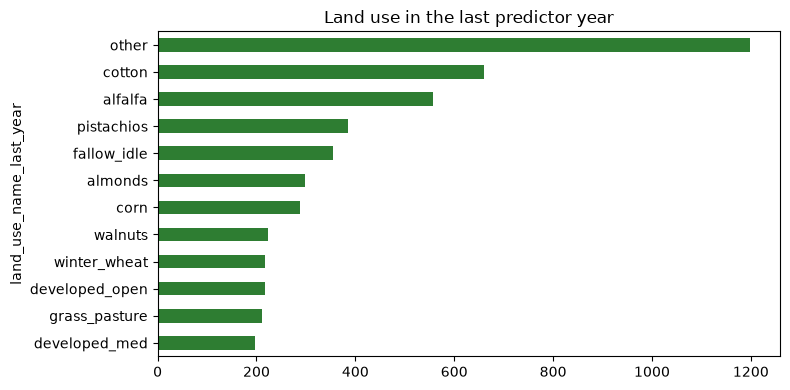

In [10]:
# Land use: what covers the area, and how much of it is cropland
print(df["land_use_name_last_year"].value_counts().head(12))
df["land_use_name_last_year"].value_counts().head(12).plot(kind="barh", color="#2E7D32")
plt.title("Land use in the last predictor year"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

count     5192.000000
mean     34201.246918
std       8318.868808
min      17192.000000
25%      27318.000000
50%      34235.000000
75%      41226.250000
max      52383.000000
Name: dist_to_nearest_well_m, dtype: float64


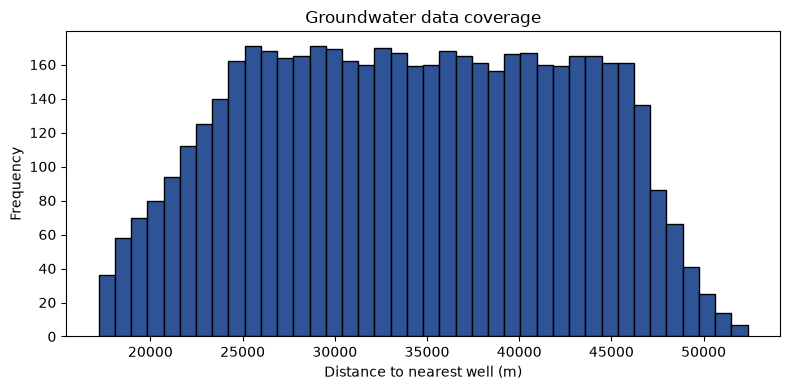

In [11]:
# Groundwater coverage: every cell is filled from its NEAREST well, so distance shows how far
# a value really is from a measurement.
print(df["dist_to_nearest_well_m"].describe())
df["dist_to_nearest_well_m"].plot(kind="hist", bins=40, color="#2F5496", edgecolor="black")
plt.xlabel("Distance to nearest well (m)"); plt.title("Groundwater data coverage"); plt.tight_layout(); plt.show()

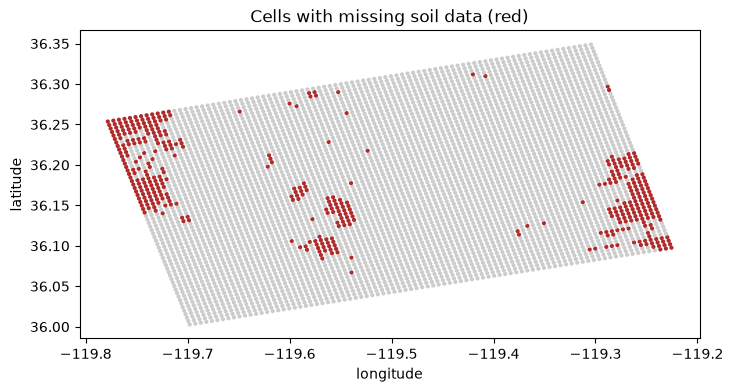

In [12]:
# Where is soil data missing? (checks whether gaps are clustered in space)
miss_soil = df["clay_pct"].isna()
plt.scatter(df.longitude, df.latitude, s=4, c=np.where(miss_soil, "#B02A2A", "#CCCCCC"))
plt.title("Cells with missing soil data (red)"); plt.xlabel("longitude"); plt.ylabel("latitude"); plt.show()

In [13]:
# Plausible ranges
cols = ["gw_decline_m_per_yr_2016_2019", "gw_mean_depth_m", "elevation_m", "slope_deg", "clay_pct", "sand_pct", "silt_pct"]
df[cols].agg(["min", "max"]).T

,min,max
gw_decline_m_per_yr_2016_2019,-6.971955,1.508458
gw_mean_depth_m,34.538920,75.552300
elevation_m,50.687630,100.534241
slope_deg,0.000000,11.156855
clay_pct,7.500000,70.000000
sand_pct,1.000000,71.300000
silt_pct,16.000000,68.900000


### Findings from this first look

- **Soil gaps:** about 6% of cells have no soil map unit and about 8% are missing the soil properties (clay, sand, silt, organic matter and others). I have no fix for this yet. The map above shows where they fall; I still need to decide whether to drop, impute or flag these cells, and this ties to the "no-data" state in my Milestone 2 plan.
- **Groundwater is interpolated by nearest well:** no cell is missing a groundwater value, but that is only because each cell takes its nearest well's value. The distance histogram shows how far many cells are from a real measurement. Values for far-away cells are weakly supported.
- **No label yet:** the InSAR displacement and the susceptibility class are not in this file. Without them I cannot check class balance. This is the main gap before modeling.
- **Spatial coverage:** the dataset covers the whole bounding box, but the groundwater source was limited to a sample of wells in Tulare and Kings counties, so coverage is uneven.
- **My own observation from the outputs above:** (add one sentence here after you run the cells, for example the most common land use, or how far the typical cell is from a well).

## 5. Data provenance
See `README.md`. Groundwater: CA DWR periodic groundwater level measurements. Land use: USDA NASS Cropland Data Layer. Soil: USDA NRCS Soil Data Access (SSURGO). Elevation: USGS 3DEP. Retrieval date and license text are recorded there.